In [1]:
#google drive a bağlanma
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Bu çalışmada k-en yakın komşu (kNN) algoritması, 18 boyutlu prosodik özellik vektörleri üzerinde eğitilmiş ve tüm özellikler sıfır ortalama ve birim varyansa standartlaştırılmıştır. En uygun k değeri, eğitim verisi üzerinde 5 katlı çapraz doğrulama ile belirlenmiştir. Çok sınıflı sınıflandırma problemi, k en yakın komşu arasında çoğunluk oylaması kullanılarak çözülmüştür. Veri sızıntısını önlemek amacıyla veri seti cümle bazlı olarak ayrılmıştır.

📥 Dosyalar taranıyor...

📊 VERİ SETİ İSTATİSTİKLERİ
🔹 Klasörde bulunan toplam ses: 360
🔹 Özellik çıkarımı başarılı (Kullanılacak): 360

📝 Eğitim seti boyutu: 288
📝 Test seti boyutu: 72



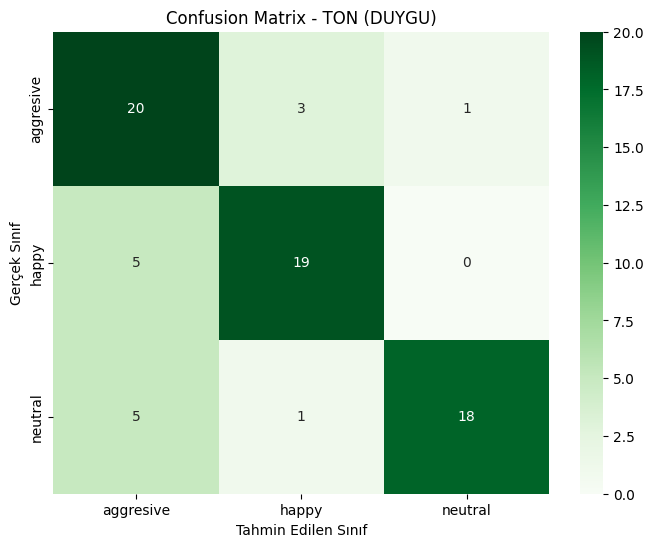

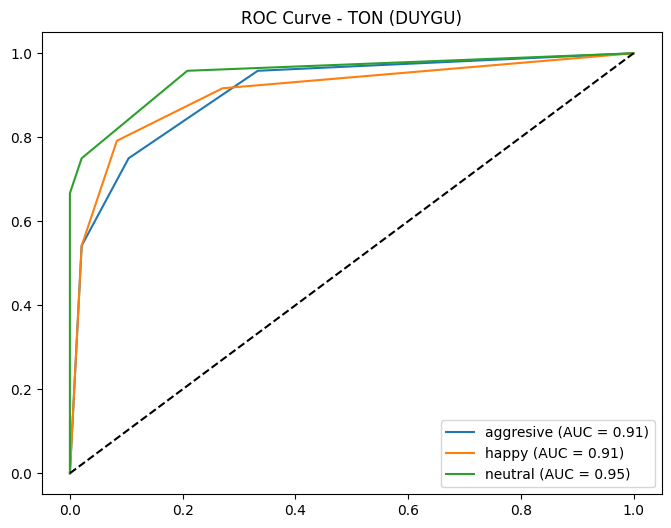

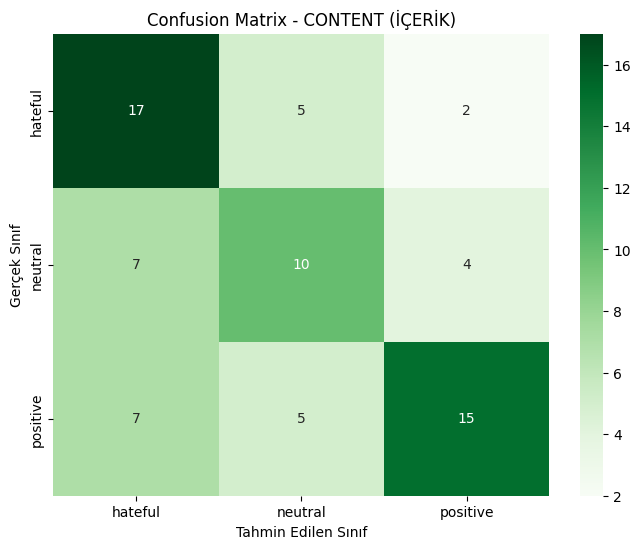

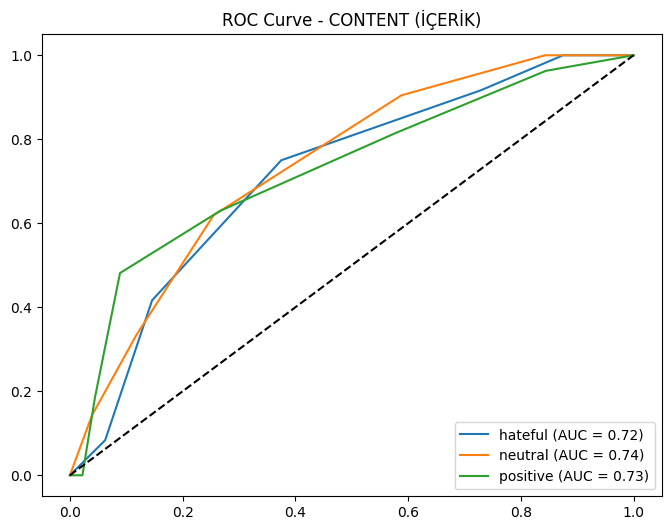


============================== TON RAPORU ==============================
              precision    recall  f1-score   support

   aggresive       0.67      0.83      0.74        24
       happy       0.83      0.79      0.81        24
     neutral       0.95      0.75      0.84        24

    accuracy                           0.79        72
   macro avg       0.81      0.79      0.80        72
weighted avg       0.81      0.79      0.80        72


============================== İÇERİK RAPORU ==============================
              precision    recall  f1-score   support

     hateful       0.55      0.71      0.62        24
     neutral       0.50      0.48      0.49        21
    positive       0.71      0.56      0.62        27

    accuracy                           0.58        72
   macro avg       0.59      0.58      0.58        72
weighted avg       0.60      0.58      0.58        72



In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import joblib
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# 1. ÖZELLİK ÇIKARIMI
# ============================================================
def extract_prosodic_features(y, sr):
    try:
        rms = librosa.feature.rms(y=y).ravel()
        zcr = librosa.feature.zero_crossing_rate(y).ravel()
        onset_env = librosa.onset.onset_strength(y=y, sr=sr)
        tempo = librosa.beat.tempo(onset_envelope=onset_env, sr=sr)[0]
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        mfcc_mean = mfcc.mean(axis=1).ravel()
        return np.concatenate([[rms.mean(), rms.std()], [zcr.mean(), zcr.std()], [float(tempo)], mfcc_mean]).astype(np.float32)
    except: return None

# ============================================================
# 2. VERİ HAZIRLAMA (SAYI TAKİBİ EKLENDİ)
# ============================================================
def prepare_knn_dataset(csv_path, audio_dir):
    df = pd.read_csv(csv_path)
    X_pros, y_tone, y_content, sentence_ids = [], [], [], []

    found_files = 0
    print("📥 Dosyalar taranıyor...")

    for _, row in df.iterrows():
        path = os.path.join(audio_dir, row["name"])
        if os.path.exists(path):
            found_files += 1
            try:
                y, sr = librosa.load(path, sr=22050)
                pros = extract_prosodic_features(y, sr)
                if pros is not None:
                    X_pros.append(pros)
                    y_tone.append(row["tone"])
                    y_content.append(row["content"])
                    sentence_ids.append(row["sentence_id"])
            except: continue

    # İstatistiki Bilgileri Yazdır
    print("\n" + "="*40)
    print(f"📊 VERİ SETİ İSTATİSTİKLERİ")
    print(f"🔹 Klasörde bulunan toplam ses: {found_files}")
    print(f"🔹 Özellik çıkarımı başarılı (Kullanılacak): {len(X_pros)}")
    print("="*40 + "\n")

    return np.array(X_pros), np.array(y_tone), np.array(y_content), np.array(sentence_ids)

# ============================================================
# 3. GÖRSELLEŞTİRME
# ============================================================
def plot_results(y_true, y_pred, y_score, classes, title_suffix):
    # Confusion Matrix
    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes)
    plt.title(f'Confusion Matrix - {title_suffix}')
    plt.ylabel('Gerçek Sınıf')
    plt.xlabel('Tahmin Edilen Sınıf')
    plt.show()

    # ROC AUC
    n_classes = len(classes)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    plt.figure(figsize=(8, 6))
    for i in range(n_classes):
        if n_classes > 1:
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
        else: # İkili sınıflandırma durumu için
            fpr, tpr, _ = roc_curve(y_true, y_score[:, 1])

        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{classes[i]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f'ROC Curve - {title_suffix}')
    plt.legend(loc="lower right")
    plt.show()

# ============================================================
# 4. EĞİTİM VE SONUÇLANDIRMA
# ============================================================
def train_and_evaluate(csv_path, audio_dir):
    X, y_t, y_c, ids = prepare_knn_dataset(csv_path, audio_dir)

    if len(X) == 0:
        print("❌ Hata: İşlenecek veri bulunamadı!")
        return

    le_tone = LabelEncoder()
    le_content = LabelEncoder()
    y_t_enc = le_tone.fit_transform(y_t)
    y_c_enc = le_content.fit_transform(y_c)

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(gss.split(X, y_c_enc, groups=ids))

    X_train, X_test = X[train_idx], X[test_idx]
    y_t_train, y_t_test = y_t_enc[train_idx], y_t_enc[test_idx]
    y_c_train, y_c_test = y_c_enc[train_idx], y_c_enc[test_idx]

    print(f"📝 Eğitim seti boyutu: {len(X_train)}")
    print(f"📝 Test seti boyutu: {len(X_test)}\n")

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    param_grid = {'n_neighbors': [3, 5, 7, 9, 11]}

    # TONE MODELİ
    grid_tone = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
    grid_tone.fit(X_train, y_t_train)
    knn_tone = grid_tone.best_estimator_
    t_pred = knn_tone.predict(X_test)
    t_score = knn_tone.predict_proba(X_test)

    # CONTENT MODELİ
    grid_content = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
    grid_content.fit(X_train, y_c_train)
    knn_content = grid_content.best_estimator_
    c_pred = knn_content.predict(X_test)
    c_score = knn_content.predict_proba(X_test)

    # GÖRSELLEŞTİRME VE RAPOR
    plot_results(y_t_test, t_pred, t_score, le_tone.classes_, "TON (DUYGU)")
    plot_results(y_c_test, c_pred, c_score, le_content.classes_, "CONTENT (İÇERİK)")

    print("\n" + "="*30 + " TON RAPORU " + "="*30)
    print(classification_report(y_t_test, t_pred, target_names=le_tone.classes_))

    print("\n" + "="*30 + " İÇERİK RAPORU " + "="*30)
    print(classification_report(y_c_test, c_pred, target_names=le_content.classes_))

if __name__ == "__main__":
    CSV_PATH = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/labels.csv"
    AUDIO_DIR = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/sesler"

    train_and_evaluate(CSV_PATH, AUDIO_DIR)